# 05 小兔鲜儿 - 商品详情（登录前）


本篇根据配套讲义 `rabbit-shop/05-详情模块.md` 整理，承接商品列表中的详情导航，完成**商品信息展示、轮播下标、大图预览和底部弹出层交互**。

原课把商品详情分为两个阶段：

| 阶段 | 教学内容 |
| --- | --- |
| 登录前，本篇 | 商品数据、图片交互、服务与地址弹出层 |
| 登录后，SKU 模块 | 选择规格后加入购物车、立即购买 |

本篇保留底部按钮和规格入口的页面结构，地址组件先用课程提供的静态示例，购买与真实地址选择按后续模块继续实现。详情骨架屏属于原课的课后练习。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，配套包为 `02-笔记.rar`。四张教学图片直接内嵌在 Notebook 中。

| 文件 | 本篇职责 |
| --- | --- |
| `src/pages/goods/goods.vue` | 商品详情、轮播图片、操作面板和弹出层 |
| `src/services/goods.ts` | 根据商品 ID 请求详情 |
| `src/types/goods.d.ts` | 商品详情及相关结构类型 |
| `src/pages/goods/components/ServicePanel.vue` | 服务说明静态内容、关闭事件 |
| `src/pages/goods/components/AddressPanel.vue` | 地址静态内容、关闭事件 |
| `src/types/global.d.ts` | 复用 03 提取的 `GoodsItem` |


## 准备工作

用户从商品列表点击卡片，带商品 ID 进入对应详情页。详情页面依次展示主图、价格名称描述、规格与配送入口、属性和详情图片、同类推荐，底部保留用户操作区域。

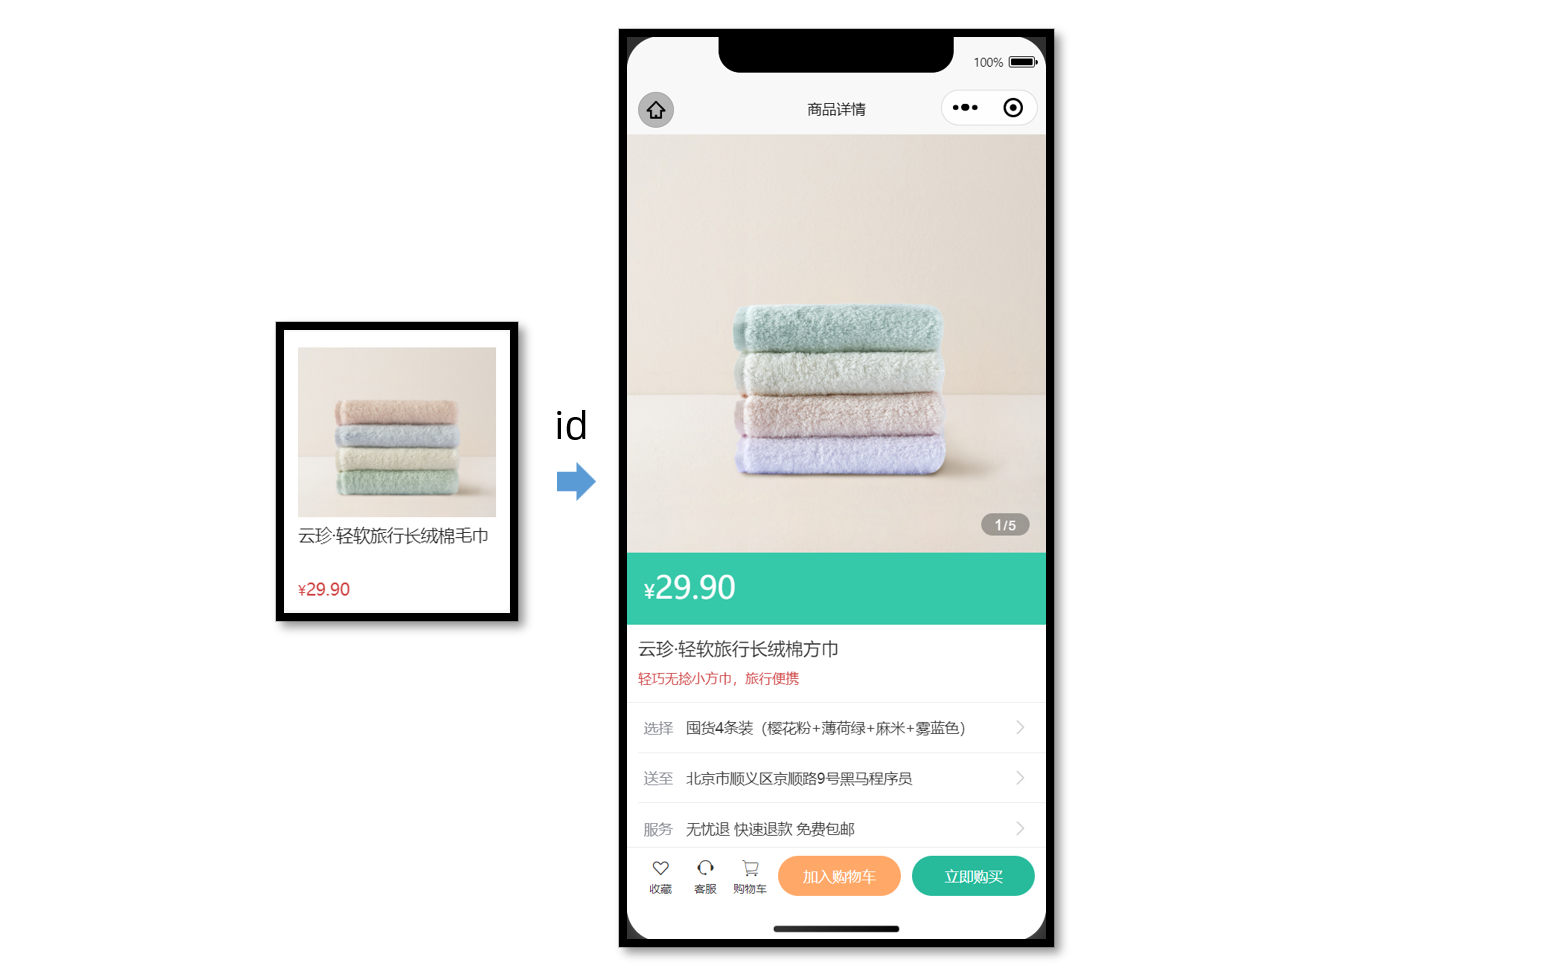


### 新建详情页与静态结构

新建 `src/pages/goods/goods.vue`，并确认 `src/pages.json` 已注册 `pages/goods/goods`。前面推荐页、分类页和同类推荐的导航都使用这一页面路径。

先准备原课的静态结构与完整 SCSS。原稿的“收获地址”统一修正为“收货地址”，其他静态商品和地址文案继续作为教学示例：


```vue
<!-- src/pages/goods/goods.vue -->
<script setup lang="ts">
// 获取屏幕边界到安全区域距离
const { safeAreaInsets } = uni.getSystemInfoSync()
</script>

<template>
  <scroll-view scroll-y class="viewport">
    <!-- 基本信息 -->
    <view class="goods">
      <!-- 商品主图 -->
      <view class="preview">
        <swiper circular>
          <swiper-item>
            <image
              mode="aspectFill"
              src="https://yanxuan-item.nosdn.127.net/99c83709ca5f9fd5c5bb35d207ad7822.png"
            />
          </swiper-item>
          <swiper-item>
            <image
              mode="aspectFill"
              src="https://yanxuan-item.nosdn.127.net/f9107d47c08f0b99c097e30055c39e1a.png"
            />
          </swiper-item>
          <swiper-item>
            <image
              mode="aspectFill"
              src="https://yanxuan-item.nosdn.127.net/754c56785cc8c39f7414752f62d79872.png"
            />
          </swiper-item>
          <swiper-item>
            <image
              mode="aspectFill"
              src="https://yanxuan-item.nosdn.127.net/ef16f8127610ef56a2a10466d6dae157.jpg"
            />
          </swiper-item>
          <swiper-item>
            <image
              mode="aspectFill"
              src="https://yanxuan-item.nosdn.127.net/1f0c3f5d32b0e804deb9b3d56ea6c3b2.png"
            />
          </swiper-item>
        </swiper>
        <view class="indicator">
          <text class="current">1</text>
          <text class="split">/</text>
          <text class="total">5</text>
        </view>
      </view>

      <!-- 商品简介 -->
      <view class="meta">
        <view class="price">
          <text class="symbol">¥</text>
          <text class="number">29.90</text>
        </view>
        <view class="name ellipsis">云珍·轻软旅行长绒棉方巾 </view>
        <view class="desc"> 轻巧无捻小方巾，旅行便携 </view>
      </view>

      <!-- 操作面板 -->
      <view class="action">
        <view class="item arrow">
          <text class="label">选择</text>
          <text class="text ellipsis"> 请选择商品规格 </text>
        </view>
        <view class="item arrow">
          <text class="label">送至</text>
          <text class="text ellipsis"> 请选择收货地址 </text>
        </view>
        <view class="item arrow">
          <text class="label">服务</text>
          <text class="text ellipsis"> 无忧退 快速退款 免费包邮 </text>
        </view>
      </view>
    </view>

    <!-- 商品详情 -->
    <view class="detail panel">
      <view class="title">
        <text>详情</text>
      </view>
      <view class="content">
        <view class="properties">
          <!-- 属性详情 -->
          <view class="item">
            <text class="label">属性名</text>
            <text class="value">属性值</text>
          </view>
          <view class="item">
            <text class="label">属性名</text>
            <text class="value">属性值</text>
          </view>
        </view>
        <!-- 图片详情 -->
        <image
          mode="widthFix"
          src="https://yanxuan-item.nosdn.127.net/a8d266886d31f6eb0d7333c815769305.jpg"
        ></image>
        <image
          mode="widthFix"
          src="https://yanxuan-item.nosdn.127.net/a9bee1cb53d72e6cdcda210071cbd46a.jpg"
        ></image>
      </view>
    </view>

    <!-- 同类推荐 -->
    <view class="similar panel">
      <view class="title">
        <text>同类推荐</text>
      </view>
      <view class="content">
        <navigator
          v-for="item in 4"
          :key="item"
          class="goods"
          hover-class="none"
          :url="`/pages/goods/goods?id=`"
        >
          <image
            class="image"
            mode="aspectFill"
            src="https://yanxuan-item.nosdn.127.net/e0cea368f41da1587b3b7fc523f169d7.png"
          ></image>
          <view class="name ellipsis">简约山形纹全棉提花毛巾</view>
          <view class="price">
            <text class="symbol">¥</text>
            <text class="number">18.50</text>
          </view>
        </navigator>
      </view>
    </view>
  </scroll-view>

  <!-- 用户操作 -->
  <view class="toolbar" :style="{ paddingBottom: safeAreaInsets?.bottom + 'px' }">
    <view class="icons">
      <button class="icons-button"><text class="icon-heart"></text>收藏</button>
      <button class="icons-button" open-type="contact">
        <text class="icon-handset"></text>客服
      </button>
      <navigator class="icons-button" url="/pages/cart/cart" open-type="switchTab">
        <text class="icon-cart"></text>购物车
      </navigator>
    </view>
    <view class="buttons">
      <view class="addcart"> 加入购物车 </view>
      <view class="buynow"> 立即购买 </view>
    </view>
  </view>
</template>

<style lang="scss">
page {
  height: 100%;
  overflow: hidden;
  display: flex;
  flex-direction: column;
}

.viewport {
  background-color: #f4f4f4;
}

.panel {
  margin-top: 20rpx;
  background-color: #fff;
  .title {
    display: flex;
    justify-content: space-between;
    align-items: center;
    height: 90rpx;
    line-height: 1;
    padding: 30rpx 60rpx 30rpx 6rpx;
    position: relative;
    text {
      padding-left: 10rpx;
      font-size: 28rpx;
      color: #333;
      font-weight: 600;
      border-left: 4rpx solid #27ba9b;
    }
    navigator {
      font-size: 24rpx;
      color: #666;
    }
  }
}

.arrow {
  &::after {
    position: absolute;
    top: 50%;
    right: 30rpx;
    content: '\e6c2';
    color: #ccc;
    font-family: 'erabbit' !important;
    font-size: 32rpx;
    transform: translateY(-50%);
  }
}

/* 商品信息 */
.goods {
  background-color: #fff;
  .preview {
    height: 750rpx;
    position: relative;
    .image {
      width: 750rpx;
      height: 750rpx;
    }
    .indicator {
      height: 40rpx;
      padding: 0 24rpx;
      line-height: 40rpx;
      border-radius: 30rpx;
      color: #fff;
      font-family: Arial, Helvetica, sans-serif;
      background-color: rgba(0, 0, 0, 0.3);
      position: absolute;
      bottom: 30rpx;
      right: 30rpx;
      .current {
        font-size: 26rpx;
      }
      .split {
        font-size: 24rpx;
        margin: 0 1rpx 0 2rpx;
      }
      .total {
        font-size: 24rpx;
      }
    }
  }
  .meta {
    position: relative;
    border-bottom: 1rpx solid #eaeaea;
    .price {
      height: 130rpx;
      padding: 25rpx 30rpx 0;
      color: #fff;
      font-size: 34rpx;
      box-sizing: border-box;
      background-color: #35c8a9;
    }
    .number {
      font-size: 56rpx;
    }
    .brand {
      width: 160rpx;
      height: 80rpx;
      overflow: hidden;
      position: absolute;
      top: 26rpx;
      right: 30rpx;
    }
    .name {
      max-height: 88rpx;
      line-height: 1.4;
      margin: 20rpx;
      font-size: 32rpx;
      color: #333;
    }
    .desc {
      line-height: 1;
      padding: 0 20rpx 30rpx;
      font-size: 24rpx;
      color: #cf4444;
    }
  }
  .action {
    padding-left: 20rpx;
    .item {
      height: 90rpx;
      padding-right: 60rpx;
      border-bottom: 1rpx solid #eaeaea;
      font-size: 26rpx;
      color: #333;
      position: relative;
      display: flex;
      align-items: center;
      &:last-child {
        border-bottom: 0 none;
      }
    }
    .label {
      width: 60rpx;
      color: #898b94;
      margin: 0 16rpx 0 10rpx;
    }
    .text {
      flex: 1;
      -webkit-line-clamp: 1;
    }
  }
}

/* 商品详情 */
.detail {
  padding-left: 20rpx;
  .content {
    margin-left: -20rpx;
    .image {
      width: 100%;
    }
  }
  .properties {
    padding: 0 20rpx;
    margin-bottom: 30rpx;
    .item {
      display: flex;
      line-height: 2;
      padding: 10rpx;
      font-size: 26rpx;
      color: #333;
      border-bottom: 1rpx dashed #ccc;
    }
    .label {
      width: 200rpx;
    }
    .value {
      flex: 1;
    }
  }
}

/* 同类推荐 */
.similar {
  .content {
    padding: 0 20rpx 200rpx;
    background-color: #f4f4f4;
    display: flex;
    flex-wrap: wrap;
    .goods {
      width: 340rpx;
      padding: 24rpx 20rpx 20rpx;
      margin: 20rpx 7rpx;
      border-radius: 10rpx;
      background-color: #fff;
    }
    .image {
      width: 300rpx;
      height: 260rpx;
    }
    .name {
      height: 80rpx;
      margin: 10rpx 0;
      font-size: 26rpx;
      color: #262626;
    }
    .price {
      line-height: 1;
      font-size: 20rpx;
      color: #cf4444;
    }
    .number {
      font-size: 26rpx;
      margin-left: 2rpx;
    }
  }
  navigator {
    &:nth-child(even) {
      margin-right: 0;
    }
  }
}

/* 底部工具栏 */
.toolbar {
  position: fixed;
  left: 0;
  right: 0;
  bottom: 0;
  z-index: 1;
  background-color: #fff;
  height: 100rpx;
  padding: 0 20rpx var(--window-bottom);
  border-top: 1rpx solid #eaeaea;
  display: flex;
  justify-content: space-between;
  align-items: center;
  box-sizing: content-box;
  .buttons {
    display: flex;
    & > view {
      width: 220rpx;
      text-align: center;
      line-height: 72rpx;
      font-size: 26rpx;
      color: #fff;
      border-radius: 72rpx;
    }
    .addcart {
      background-color: #ffa868;
    }
    .buynow,
    .payment {
      background-color: #27ba9b;
      margin-left: 20rpx;
    }
  }
  .icons {
    padding-right: 10rpx;
    display: flex;
    align-items: center;
    flex: 1;
    .icons-button {
      flex: 1;
      text-align: center;
      line-height: 1.4;
      padding: 0;
      margin: 0;
      border-radius: 0;
      font-size: 20rpx;
      color: #333;
      background-color: #fff;
      &::after {
        border: none;
      }
    }
    text {
      display: block;
      font-size: 34rpx;
    }
  }
}
</style>
```

这一步使用固定商品数据、5 张主图和静态推荐卡片，目的是先验证页面结构。模板的图标字体、`ellipsis` 等类沿用课程模板。

原课使用 `uni.getSystemInfoSync()` 取得 `safeAreaInsets`，把 `bottom` 作为底部工具栏的额外 padding，避免按钮贴在底部系统操作区域。这里的数值单位为 **px**，并非 `rpx`；若当前平台没有返回该字段，绑定值可以按 `(safeAreaInsets?.bottom ?? 0) + 'px'` 回退。

客服按钮使用小程序的 `open-type="contact"`。静态版本的购物车导航使用 `open-type="switchTab"`，因为它指向底部导航页面。收藏、加入购物车和立即购买在本节尚未接入业务动作。


### 获取页面参数

列表导航应带商品 ID，例如 `/pages/goods/goods?id=商品ID`。在详情页的 `<script setup lang="ts">` 中读取原课约定的页面参数：


```typescript
// 接收页面参数
const query = defineProps<{
  id: string
}>()
```

通过 `query.id` 查询当前商品。直接在开发工具中调试该页面时，也要传入一个有效商品 ID。


### 封装商品详情请求

| 项目 | 内容 |
| --- | --- |
| 方法 | `GET` |
| 路径 | `/goods` |
| Query | `id`，必需，无默认值 |
| 返回数据 | 当前商品的详情对象 |

新建 `src/services/goods.ts`，复用 01 的请求函数：

> **原稿补齐**：接口片段省略了 `http` 和 `GoodsResult` 的导入，下面补齐对应模块路径。


```typescript
import { http } from '@/utils/http'
import type { GoodsResult } from '@/types/goods'

/**
 * 商品详情
 * @param id 商品id
 */
export const getGoodsByIdAPI = (id: string) => {
  return http<GoodsResult>({
    method: 'GET',
    url: '/goods',
    data: { id },
  })
}
```

`data: { id }` 随 GET 请求发送查询参数。`http<GoodsResult>` 仍返回 01 定义的响应外层，商品对象在 `res.result` 中。


### 声明商品详情类型

新建 `src/types/goods.d.ts`，复用通用商品类型 `GoodsItem`：


```typescript
import type { GoodsItem } from './global'

/** 商品信息 */
export type GoodsResult = {
  /** id */
  id: string
  /** 商品名称 */
  name: string
  /** 商品描述 */
  desc: string
  /** 当前价格 */
  price: number
  /** 原价 */
  oldPrice: number
  /** 商品详情: 包含详情属性 + 详情图片 */
  details: Details
  /** 主图图片集合[ 主图图片链接 ] */
  mainPictures: string[]
  /** 同类商品[ 商品信息 ] */
  similarProducts: GoodsItem[]
  /** sku集合[ sku信息 ] */
  skus: SkuItem[]
  /** 可选规格集合备注[ 可选规格信息 ] */
  specs: SpecItem[]
  /** 用户地址列表[ 地址信息 ] */
  userAddresses: AddressItem[]
}

/** 商品详情: 包含详情属性 + 详情图片 */
export type Details = {
  /** 商品属性集合[ 属性信息 ] */
  properties: DetailsPropertyItem[]
  /** 商品详情图片集合[ 图片链接 ] */
  pictures: string[]
}

/** 属性信息 */
export type DetailsPropertyItem = {
  /** 属性名称 */
  name: string
  /** 属性值 */
  value: string
}

/** sku信息 */
export type SkuItem = {
  /** id */
  id: string
  /** 库存 */
  inventory: number
  /** 原价 */
  oldPrice: number
  /** sku图片 */
  picture: string
  /** 当前价格 */
  price: number
  /** sku编码 */
  skuCode: string
  /** 规格集合[ 规格信息 ] */
  specs: SkuSpecItem[]
}

/** 规格信息 */
export type SkuSpecItem = {
  /** 规格名称 */
  name: string
  /** 可选值名称 */
  valueName: string
}

/** 可选规格信息 */
export type SpecItem = {
  /** 规格名称 */
  name: string
  /** 可选值集合[ 可选值信息 ] */
  values: SpecValueItem[]
}

/** 可选值信息 */
export type SpecValueItem = {
  /** 是否可售 */
  available: boolean
  /** 可选值备注 */
  desc: string
  /** 可选值名称 */
  name: string
  /** 可选值图片链接 */
  picture: string
}

/** 地址信息 */
export type AddressItem = {
  /** 收货人姓名 */
  receiver: string
  /** 联系方式 */
  contact: string
  /** 省份编码 */
  provinceCode: string
  /** 城市编码 */
  cityCode: string
  /** 区/县编码 */
  countyCode: string
  /** 详细地址 */
  address: string
  /** 默认地址，1为是，0为否 */
  isDefault: number
  /** 收货地址 id */
  id: string
  /** 省市区 */
  fullLocation: string
}
```

本篇主要渲染以下数据：

| 字段 | 展示区域 |
| --- | --- |
| `mainPictures` | 商品主图轮播和大图预览 |
| `price`、`name`、`desc` | 价格、名称、描述 |
| `details.properties` | 属性名称和值 |
| `details.pictures` | 商品详情长图 |
| `similarProducts` | 同类商品推荐 |

`skus`、`specs`、`userAddresses` 一并保留在原课的完整响应类型中。本篇声明它们的结构，后面的 SKU、地址等模块再实现相应交互。

`SpecItem` 描述可选择的规格项和候选值；`SkuItem` 描述具体规格组合对应的价格、库存等信息。此处先读懂响应层次，不提前实现规格选择。


### 保存数据并渲染

下面是原课总代码中的数据获取片段，放在详情页脚本中；`getGoodsByIdAPI`、`GoodsResult`、`onLoad` 和 `ref` 的导入见最后的完整示例：


```typescript
const goods = ref<GoodsResult>()
const getGoodsByIdData = async () => {
  const res = await getGoodsByIdAPI(query.id)
  goods.value = res.result
}

// 页面加载
onLoad(() => {
  getGoodsByIdData()
})
```

页面加载时查询当前 ID，把结果存入 `goods`，再用模板绑定替换静态数据：

| 区域 | 渲染方式 |
| --- | --- |
| 商品简介 | `goods?.price`、`goods?.name`、`goods?.desc` |
| 属性列表 | 遍历 `goods?.details.properties` |
| 详情图片 | 遍历 `goods?.details.pictures`，使用 `mode="widthFix"` |
| 同类推荐 | 遍历 `goods?.similarProducts`，导航带每项的 `id` |

`goods` 初始没有值，所以模板使用可选链处理尚未取得数据的阶段。属性名作为 key，图片 URL 作为图片 key，商品 ID 作为推荐卡片 key。

`widthFix` 让详情图片保持宽高比例，随显示宽度调整高度；主图的 `aspectFill` 则用于填满展示区域。最后的完整模板展示了各区域的实际绑定。


## 轮播图交互

主图轮播需要两种交互：滑动时更新“当前张数 / 总张数”，点击图片时进入大图预览。

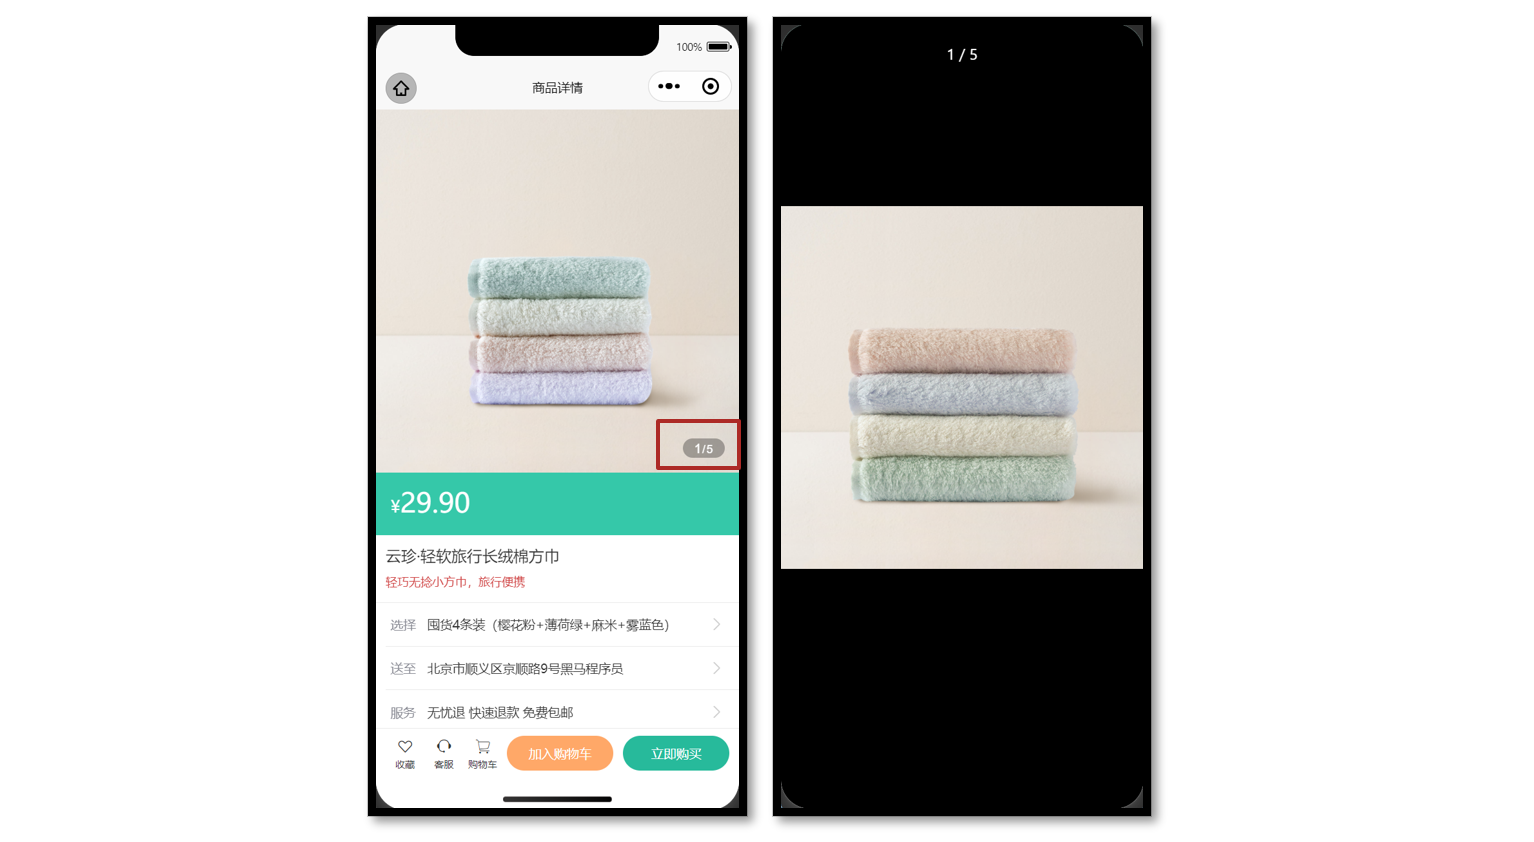


### 更新下标与预览图片

在详情页中增加下面的局部逻辑。`goods` 继续使用上一节定义的商品状态；原稿片段省略了 `ref` 导入，这里补齐：


```vue
<script setup lang="ts">
import { ref } from 'vue'
// 轮播图变化时
const currentIndex = ref(0)
const onChange: UniHelper.SwiperOnChange = (ev) => {
  currentIndex.value = ev.detail.current
}

// 点击图片时
const onTapImage = (url: string) => {
  // 大图预览
  uni.previewImage({
    current: url,
    urls: goods.value!.mainPictures,
  })
}
</script>

<template>
  <!-- 商品主图 -->
  <view class="preview">
    <swiper @change="onChange" circular>
      <swiper-item v-for="item in goods?.mainPictures" :key="item">
        <image @tap="onTapImage(item)" mode="aspectFill" :src="item" />
      </swiper-item>
    </swiper>
    <view class="indicator">
      <text class="current">{{ currentIndex + 1 }}</text>
      <text class="split">/</text>
      <text class="total">{{ goods?.mainPictures.length }}</text>
    </view>
  </view>
</template>
```

`ev.detail.current` 是从 0 开始的下标，显示给用户时使用 `currentIndex + 1`。总数从 `mainPictures.length` 取得，不再写死为 5。

`uni.previewImage` 的 `current` 指定当前点击的图片，`urls` 提供整组主图，用户可以在预览中继续切换。这里的 `goods.value!` 是非空断言；原课是在已渲染出的主图上触发点击，前提是商品数据已经取得。

**跟做检查**：滑动到不同主图，确认显示的张数正确；点击中间一张图片，预览应从该张开始，并能浏览其他主图。


## 弹出层交互

使用 01 已引入的 uni-ui 组件 [uni-popup](https://uniapp.dcloud.net.cn/component/uniui/uni-popup.html)，从底部展示服务说明和地址面板。

本节先准备两个业务组件，再在详情页共用一个弹出层，通过名称决定显示哪个组件。

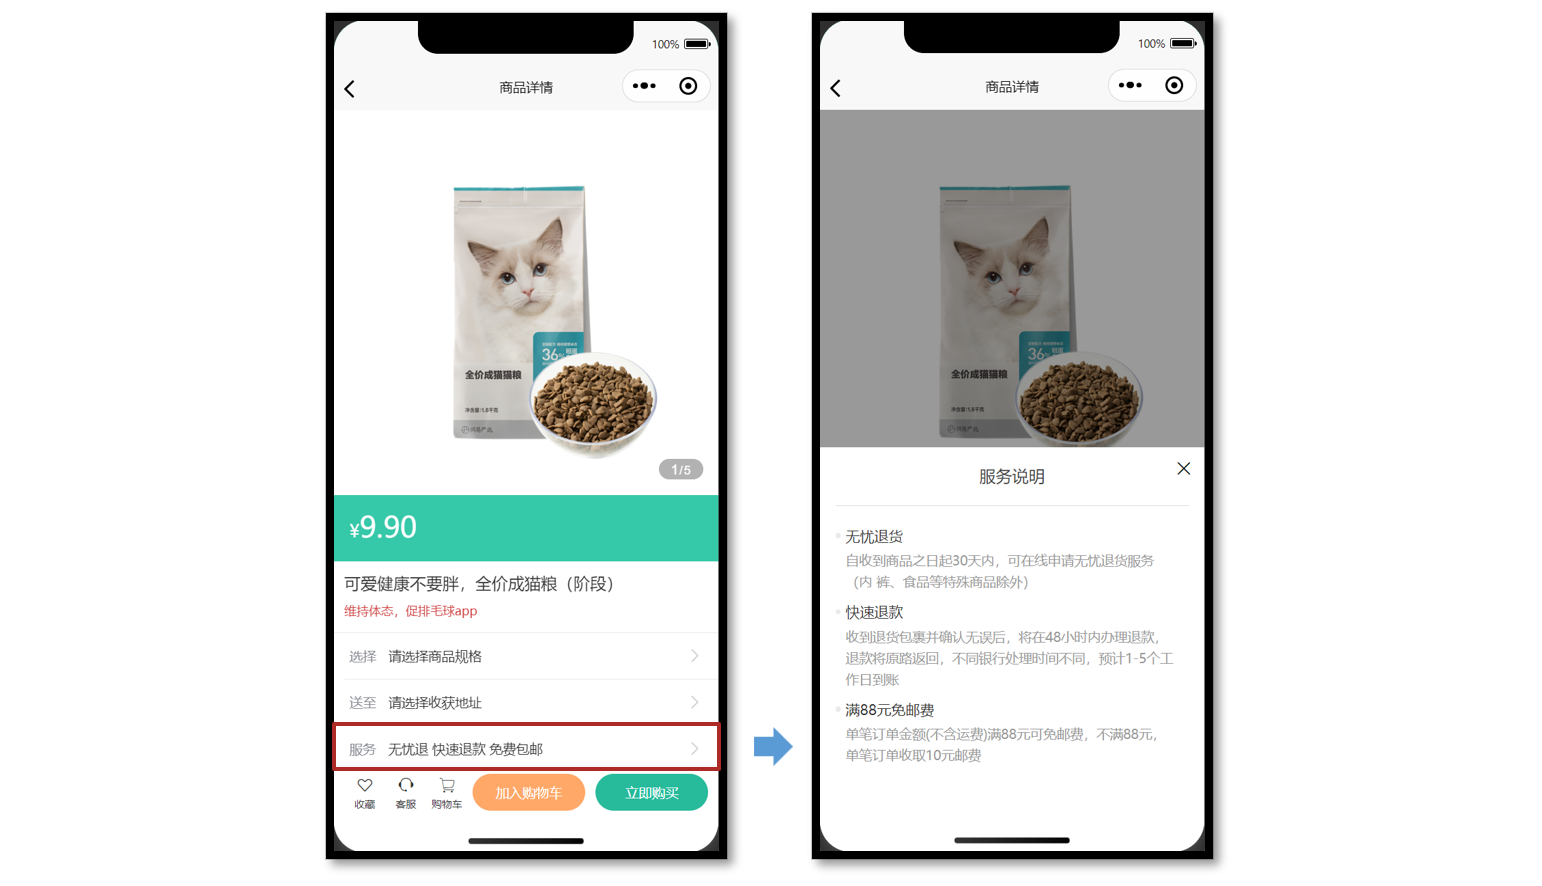


### 组件 1：服务说明

新建 `src/pages/goods/components/ServicePanel.vue`，先放入原课的静态内容和 SCSS：


```vue
<!-- ServicePanel.vue -->
<script setup lang="ts">
//
</script>

<template>
  <view class="service-panel">
    <!-- 关闭按钮 -->
    <text class="close icon-close"></text>
    <!-- 标题 -->
    <view class="title">服务说明</view>
    <!-- 内容 -->
    <view class="content">
      <view class="item">
        <view class="dt">无忧退货</view>
        <view class="dd">
          自收到商品之日起30天内，可在线申请无忧退货服务（食品等特殊商品除外）
        </view>
      </view>
      <view class="item">
        <view class="dt">快速退款</view>
        <view class="dd">
          收到退货包裹并确认无误后，将在48小时内办理退款，
          退款将原路返回，不同银行处理时间不同，预计1-5个工作日到账
        </view>
      </view>
      <view class="item">
        <view class="dt">满88元免邮费</view>
        <view class="dd">
          单笔订单金额(不含运费)满88元可免邮费，不满88元， 单笔订单收取10元邮费
        </view>
      </view>
    </view>
  </view>
</template>

<style lang="scss">
.service-panel {
  padding: 0 30rpx;
  border-radius: 10rpx 10rpx 0 0;
  position: relative;
  background-color: #fff;
}

.title {
  line-height: 1;
  padding: 40rpx 0;
  text-align: center;
  font-size: 32rpx;
  font-weight: normal;
  border-bottom: 1rpx solid #ddd;
  color: #444;
}

.close {
  position: absolute;
  right: 24rpx;
  top: 24rpx;
}

.content {
  padding: 20rpx 20rpx 100rpx 20rpx;

  .item {
    margin-top: 20rpx;
  }

  .dt {
    margin-bottom: 10rpx;
    font-size: 28rpx;
    color: #333;
    font-weight: 500;
    position: relative;

    &::before {
      content: '';
      width: 10rpx;
      height: 10rpx;
      border-radius: 50%;
      background-color: #eaeaea;
      transform: translateY(-50%);
      position: absolute;
      top: 50%;
      left: -20rpx;
    }
  }

  .dd {
    line-height: 1.6;
    font-size: 26rpx;
    color: #999;
  }
}
</style>
```

面板展示无忧退货、快速退款和运费说明。右上角的关闭图标此时只有外观，下一节通过组件事件连接到弹出层关闭动作。


### 组件 2：收货地址

新建 `src/pages/goods/components/AddressPanel.vue`，先放入原课静态结构：


```vue
<!-- AddressPanel.vue -->
<script setup lang="ts">
//
</script>

<template>
  <view class="address-panel">
    <!-- 关闭按钮 -->
    <text class="close icon-close"></text>
    <!-- 标题 -->
    <view class="title">配送至</view>
    <!-- 内容 -->
    <view class="content">
      <view class="item">
        <view class="user">李明 13824686868</view>
        <view class="address">北京市顺义区后沙峪地区安平北街6号院</view>
        <text class="icon icon-checked"></text>
      </view>
      <view class="item">
        <view class="user">王东 13824686868</view>
        <view class="address">北京市顺义区后沙峪地区安平北街6号院</view>
        <text class="icon icon-ring"></text>
      </view>
      <view class="item">
        <view class="user">张三 13824686868</view>
        <view class="address">北京市朝阳区孙河安平北街6号院</view>
        <text class="icon icon-ring"></text>
      </view>
    </view>
    <view class="footer">
      <view class="button primary"> 新建地址 </view>
      <view v-if="false" class="button primary">确定</view>
    </view>
  </view>
</template>

<style lang="scss">
.address-panel {
  padding: 0 30rpx;
  border-radius: 10rpx 10rpx 0 0;
  position: relative;
  background-color: #fff;
}

.title {
  line-height: 1;
  padding: 40rpx 0;
  text-align: center;
  font-size: 32rpx;
  font-weight: normal;
  border-bottom: 1rpx solid #ddd;
  color: #444;
}

.close {
  position: absolute;
  right: 24rpx;
  top: 24rpx;
}

.content {
  min-height: 300rpx;
  max-height: 540rpx;
  overflow: auto;
  padding: 20rpx;
  .item {
    padding: 30rpx 50rpx 30rpx 60rpx;
    background-size: 40rpx;
    background-repeat: no-repeat;
    background-position: 0 center;
    background-image: url(https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/images/locate.png);
    position: relative;
  }
  .icon {
    color: #999;
    font-size: 40rpx;
    transform: translateY(-50%);
    position: absolute;
    top: 50%;
    right: 0;
  }
  .icon-checked {
    color: #27ba9b;
  }
  .icon-ring {
    color: #444;
  }
  .user {
    font-size: 28rpx;
    color: #444;
    font-weight: 500;
  }
  .address {
    font-size: 26rpx;
    color: #666;
  }
}

.footer {
  display: flex;
  justify-content: space-between;
  padding: 20rpx 0 40rpx;
  font-size: 28rpx;
  color: #444;

  .button {
    flex: 1;
    height: 72rpx;
    text-align: center;
    line-height: 72rpx;
    margin: 0 20rpx;
    color: #fff;
    border-radius: 72rpx;
  }

  .primary {
    color: #fff;
    background-color: #27ba9b;
  }

  .secondary {
    background-color: #ffa868;
  }
}
</style>
```

姓名、联系方式和地址是原课提供的示例数据。当前用图标展示选中外观，“新建地址”按钮与隐藏的“确定”按钮用于预留结构。

本篇只实现面板展示和关闭，没有把 `goods.userAddresses` 渲染为真实地址列表，也没有完成地址选择、新建或回填流程。


### 父页面打开弹出层

在 `goods.vue` 中导入两个业务面板，通过组件引用取得 `uni-popup` 的实例。原稿局部片段缺少 `ref` 导入，这里补齐：


```vue
<script setup lang="ts">
import AddressPanel from './components/AddressPanel.vue'
import ServicePanel from './components/ServicePanel.vue'
import { ref } from 'vue'

// uni-ui 弹出层组件 ref
const popup = ref<{
  open: (type?: UniHelper.UniPopupType) => void
  close: () => void
}>()

// 弹出层条件渲染
const popupName = ref<'address' | 'service'>()
const openPopup = (name: typeof popupName.value) => {
  // 修改弹出层名称
  popupName.value = name
  // 打开弹出层
  popup.value?.open()
}
</script>

<template>
  <!-- 操作面板 -->
  <view class="action">
    <view class="item arrow">
      <text class="label">选择</text>
      <text class="text ellipsis"> 请选择商品规格 </text>
    </view>
    <view @tap="openPopup('address')" class="item arrow">
      <text class="label">送至</text>
      <text class="text ellipsis"> 请选择收货地址 </text>
    </view>
    <view @tap="openPopup('service')" class="item arrow">
      <text class="label">服务</text>
      <text class="text ellipsis"> 无忧退 快速退款 免费包邮 </text>
    </view>
  </view>
  <!-- uni-ui 弹出层 -->
  <uni-popup ref="popup" type="bottom" background-color="#fff">
    <AddressPanel v-if="popupName === 'address'" @close="popup?.close()" />
    <ServicePanel v-if="popupName === 'service'" @close="popup?.close()" />
  </uni-popup>
</template>
```

`popup` 的类型声明列出本节使用的 `open`、`close` 方法。实例未就绪时，可选链 `popup.value?.open()` 避免直接访问不存在的引用。

`popupName` 限定为 `'address'` 或 `'service'`。点击“送至”或“服务”时，先设置面板名称，再打开弹出层。`type="bottom"` 指定底部弹出，`background-color="#fff"` 设置背景。

两个业务组件使用 `v-if` 按名称选择，复用同一个弹出层。原课的“选择商品规格”入口此处还没有绑定规格面板。


### 子组件通知父页面关闭

在 `ServicePanel.vue` 与 `AddressPanel.vue` 的 `<script setup lang="ts">` 中加入 `defineEmits`，并给各自的关闭图标添加点击事件。以服务面板为例：


```vue
<script setup lang="ts">
// 子调父
const emit = defineEmits<{
  (event: 'close'): void
}>()
</script>

<template>
  <view class="service-panel">
    <!-- 关闭按钮 -->
    <text class="close icon-close" @tap="emit('close')"></text>
    ...省略
  </view>
</template>
```

这是一段局部示例：合并时保留之前的完整内容和 SCSS。地址面板同样声明 `close` 事件并绑定 `@tap="emit('close')"`，它的根类名仍为 `address-panel`。

交互方向：

| 动作 | 实现 |
| --- | --- |
| 父页面打开弹出层 | 用组件引用调用 `popup.open()` |
| 子面板点击关闭 | `emit('close')` 通知父页面 |
| 父页面响应事件 | `@close="popup?.close()"` 调用关闭方法 |

子面板只发出事件，父页面负责控制外层弹出层。模板中的 ref 自动解包，因此父模板使用 `popup?.close()`，脚本中则使用 `popup.value?.close()`。

**跟做检查**：分别打开地址、服务面板，关闭图标均能收起弹出层；两个入口展示的内容应对应当前名称。


## 骨架屏

原课把商品详情骨架屏作为**课后练习，要求自主独立完成**，并给出以下参考效果：

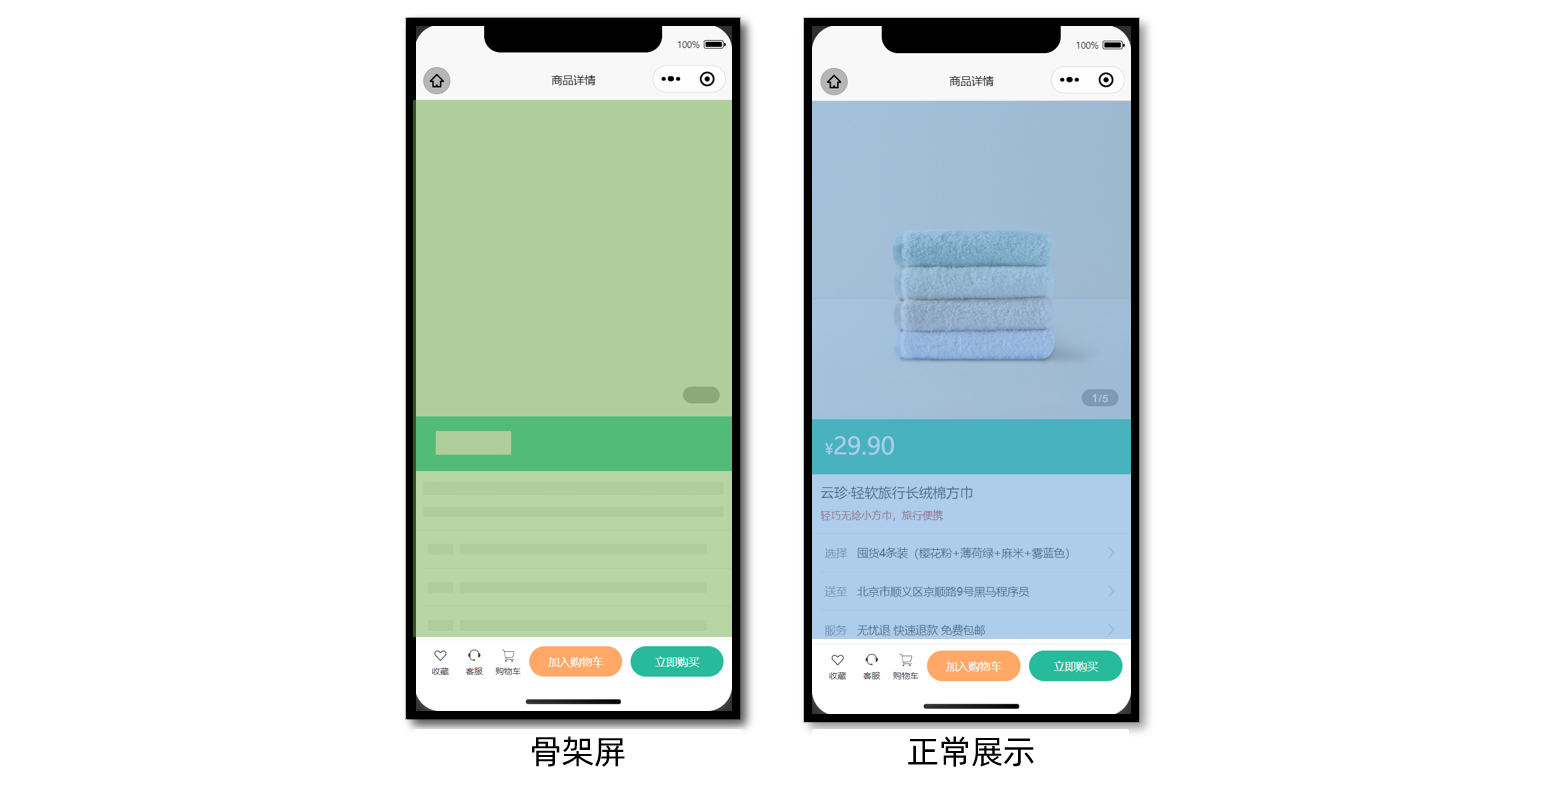


### 课后练习怎么完成

沿用 02、04 中已经介绍的生成方式：

1. 先运行能正常展示商品的详情页，再用微信开发者工具生成本页骨架。
2. 把生成的结构与样式整理成 `src/pages/goods/components/PageSkeleton.vue`。
3. 在商品查询期间显示骨架，取得详情后切换真实内容。
4. 参考图中底部操作区仍然保留，骨架主要覆盖上方商品展示区域。

以上是根据原课练习目标整理的操作提示。讲义没有给出详情骨架组件与加载状态的完整实现，最后的原课总代码也尚未接入它。

跟做时检查首次等待的占位效果和请求结束后的切换；请求失败时的状态处理也需要在练习中明确。


## 参考代码（总）

下面保留原课商品详情页的完整脚本、模板与 SCSS，合并到 `src/pages/goods/goods.vue`。原稿中的“收获地址”仍统一修正为“收货地址”。

使用前先完成 `services/goods.ts`、`types/goods.d.ts` 和两个业务面板，并按上面的关闭事件步骤完善它们。不要把前面的局部脚本再重复追加到这份完整页面中。


```vue
<script setup lang="ts">
import { getGoodsByIdAPI } from '@/services/goods'
import type { GoodsResult } from '@/types/goods'
import { onLoad } from '@dcloudio/uni-app'
import { ref } from 'vue'
import AddressPanel from './components/AddressPanel.vue'
import ServicePanel from './components/ServicePanel.vue'

// 获取屏幕边界到安全区域距离
const { safeAreaInsets } = uni.getSystemInfoSync()

// 接收页面参数
const query = defineProps<{
  id: string
}>()

// 获取商品详情信息
const goods = ref<GoodsResult>()
const getGoodsByIdData = async () => {
  const res = await getGoodsByIdAPI(query.id)
  goods.value = res.result
}

// 页面加载
onLoad(() => {
  getGoodsByIdData()
})

// 轮播图变化时
const currentIndex = ref(0)
const onChange: UniHelper.SwiperOnChange = (ev) => {
  currentIndex.value = ev.detail.current
}

// 点击图片时
const onTapImage = (url: string) => {
  // 大图预览
  uni.previewImage({
    current: url,
    urls: goods.value!.mainPictures,
  })
}

// uni-ui 弹出层组件 ref
const popup = ref<{
  open: (type?: UniHelper.UniPopupType) => void
  close: () => void
}>()

// 弹出层条件渲染
const popupName = ref<'address' | 'service'>()
const openPopup = (name: typeof popupName.value) => {
  // 修改弹出层名称
  popupName.value = name
  popup.value?.open()
}
</script>

<template>
  <scroll-view scroll-y class="viewport">
    <!-- 基本信息 -->
    <view class="goods">
      <!-- 商品主图 -->
      <view class="preview">
        <swiper @change="onChange" circular>
          <swiper-item v-for="item in goods?.mainPictures" :key="item">
            <image @tap="onTapImage(item)" mode="aspectFill" :src="item" />
          </swiper-item>
        </swiper>
        <view class="indicator">
          <text class="current">{{ currentIndex + 1 }}</text>
          <text class="split">/</text>
          <text class="total">{{ goods?.mainPictures.length }}</text>
        </view>
      </view>

      <!-- 商品简介 -->
      <view class="meta">
        <view class="price">
          <text class="symbol">¥</text>
          <text class="number">{{ goods?.price }}</text>
        </view>
        <view class="name ellipsis">{{ goods?.name }}</view>
        <view class="desc"> {{ goods?.desc }} </view>
      </view>

      <!-- 操作面板 -->
      <view class="action">
        <view class="item arrow">
          <text class="label">选择</text>
          <text class="text ellipsis"> 请选择商品规格 </text>
        </view>
        <view @tap="openPopup('address')" class="item arrow">
          <text class="label">送至</text>
          <text class="text ellipsis"> 请选择收货地址 </text>
        </view>
        <view @tap="openPopup('service')" class="item arrow">
          <text class="label">服务</text>
          <text class="text ellipsis"> 无忧退 快速退款 免费包邮 </text>
        </view>
      </view>
    </view>

    <!-- 商品详情 -->
    <view class="detail panel">
      <view class="title">
        <text>详情</text>
      </view>
      <view class="content">
        <view class="properties">
          <!-- 属性详情 -->
          <view class="item" v-for="item in goods?.details.properties" :key="item.name">
            <text class="label">{{ item.name }}</text>
            <text class="value">{{ item.value }}</text>
          </view>
        </view>
        <!-- 图片详情 -->
        <image
          v-for="item in goods?.details.pictures"
          :key="item"
          mode="widthFix"
          :src="item"
        ></image>
      </view>
    </view>

    <!-- 同类推荐 -->
    <view class="similar panel">
      <view class="title">
        <text>同类推荐</text>
      </view>
      <view class="content">
        <navigator
          v-for="item in goods?.similarProducts"
          :key="item.id"
          class="goods"
          hover-class="none"
          :url="`/pages/goods/goods?id=${item.id}`"
        >
          <image class="image" mode="aspectFill" :src="item.picture"></image>
          <view class="name ellipsis">{{ item.name }}</view>
          <view class="price">
            <text class="symbol">¥</text>
            <text class="number">{{ item.price }}</text>
          </view>
        </navigator>
      </view>
    </view>
  </scroll-view>

  <!-- 用户操作 -->
  <view class="toolbar" :style="{ paddingBottom: safeAreaInsets?.bottom + 'px' }">
    <view class="icons">
      <button class="icons-button"><text class="icon-heart"></text>收藏</button>
      <button class="icons-button" open-type="contact">
        <text class="icon-handset"></text>客服
      </button>
      <navigator class="icons-button"><text class="icon-cart"></text>购物车</navigator>
    </view>
    <view class="buttons">
      <view class="addcart"> 加入购物车 </view>
      <view class="payment"> 立即购买 </view>
    </view>
  </view>

  <!-- uni-ui 弹出层 -->
  <uni-popup ref="popup" type="bottom" background-color="#fff">
    <AddressPanel v-if="popupName === 'address'" @close="popup?.close()" />
    <ServicePanel v-if="popupName === 'service'" @close="popup?.close()" />
  </uni-popup>
</template>

<style lang="scss">
page {
  height: 100%;
  overflow: hidden;
  display: flex;
  flex-direction: column;
}

.viewport {
  background-color: #f4f4f4;
}

.panel {
  margin-top: 20rpx;
  background-color: #fff;
  .title {
    display: flex;
    justify-content: space-between;
    align-items: center;
    height: 90rpx;
    line-height: 1;
    padding: 30rpx 60rpx 30rpx 6rpx;
    position: relative;
    text {
      padding-left: 10rpx;
      font-size: 28rpx;
      color: #333;
      font-weight: 600;
      border-left: 4rpx solid #27ba9b;
    }
    navigator {
      font-size: 24rpx;
      color: #666;
    }
  }
}

.arrow {
  &::after {
    position: absolute;
    top: 50%;
    right: 30rpx;
    content: '\e6c2';
    color: #ccc;
    font-family: 'erabbit' !important;
    font-size: 32rpx;
    transform: translateY(-50%);
  }
}

/* 商品信息 */
.goods {
  background-color: #fff;
  .preview {
    height: 750rpx;
    position: relative;
    .indicator {
      height: 40rpx;
      padding: 0 24rpx;
      line-height: 40rpx;
      border-radius: 30rpx;
      color: #fff;
      font-family: Arial, Helvetica, sans-serif;
      background-color: rgba(0, 0, 0, 0.3);
      position: absolute;
      bottom: 30rpx;
      right: 30rpx;
      .current {
        font-size: 26rpx;
      }
      .split {
        font-size: 24rpx;
        margin: 0 1rpx 0 2rpx;
      }
      .total {
        font-size: 24rpx;
      }
    }
  }
  .meta {
    position: relative;
    border-bottom: 1rpx solid #eaeaea;
    .price {
      height: 130rpx;
      padding: 25rpx 30rpx 0;
      color: #fff;
      font-size: 34rpx;
      box-sizing: border-box;
      background-color: #35c8a9;
    }
    .number {
      font-size: 56rpx;
    }
    .brand {
      width: 160rpx;
      height: 80rpx;
      overflow: hidden;
      position: absolute;
      top: 26rpx;
      right: 30rpx;
    }
    .name {
      max-height: 88rpx;
      line-height: 1.4;
      margin: 20rpx;
      font-size: 32rpx;
      color: #333;
    }
    .desc {
      line-height: 1;
      padding: 0 20rpx 30rpx;
      font-size: 24rpx;
      color: #cf4444;
    }
  }
  .action {
    padding-left: 20rpx;
    .item {
      height: 90rpx;
      padding-right: 60rpx;
      border-bottom: 1rpx solid #eaeaea;
      font-size: 26rpx;
      color: #333;
      position: relative;
      display: flex;
      align-items: center;
      &:last-child {
        border-bottom: 0 none;
      }
    }
    .label {
      width: 60rpx;
      color: #898b94;
      margin: 0 16rpx 0 10rpx;
    }
    .text {
      flex: 1;
      -webkit-line-clamp: 1;
    }
  }
}

/* 商品详情 */
.detail {
  padding-left: 20rpx;
  .content {
    margin-left: -20rpx;
  }
  .properties {
    padding: 0 20rpx;
    margin-bottom: 30rpx;
    .item {
      display: flex;
      line-height: 2;
      padding: 10rpx;
      font-size: 26rpx;
      color: #333;
      border-bottom: 1rpx dashed #ccc;
    }
    .label {
      width: 200rpx;
    }
    .value {
      flex: 1;
    }
  }
}

/* 同类推荐 */
.similar {
  padding-left: 20rpx;
  .content {
    padding: 0 20rpx 20rpx;
    margin-left: -20rpx;
    background-color: #f4f4f4;
    overflow: hidden;
    navigator {
      width: 345rpx;
      padding: 24rpx 20rpx 20rpx;
      margin: 20rpx 20rpx 0 0;
      border-radius: 10rpx;
      background-color: #fff;
      float: left;
    }
    .image {
      height: 260rpx;
    }
    .name {
      height: 80rpx;
      margin: 10rpx 0;
      font-size: 26rpx;
      color: #262626;
    }
    .price {
      line-height: 1;
      font-size: 20rpx;
      color: #cf4444;
    }
    .number {
      font-size: 26rpx;
      margin-left: 2rpx;
    }
  }
  navigator {
    &:nth-child(even) {
      margin-right: 0;
    }
  }
}

/* 底部工具栏 */
.toolbar {
  background-color: #fff;
  height: 100rpx;
  padding: 0 20rpx;
  border-top: 1rpx solid #eaeaea;
  display: flex;
  justify-content: space-between;
  align-items: center;
  box-sizing: content-box;
  .buttons {
    display: flex;
    & > view {
      width: 220rpx;
      text-align: center;
      line-height: 72rpx;
      font-size: 26rpx;
      color: #fff;
      border-radius: 72rpx;
    }
    .addcart {
      background-color: #ffa868;
    }
    .payment {
      background-color: #27ba9b;
      margin-left: 20rpx;
    }
  }
  .icons {
    padding-right: 10rpx;
    display: flex;
    align-items: center;
    flex: 1;
    .icons-button {
      flex: 1;
      text-align: center;
      line-height: 1.4;
      padding: 0;
      margin: 0;
      border-radius: 0;
      font-size: 20rpx;
      color: #333;
      background-color: #fff;
    }
    text {
      display: block;
      font-size: 34rpx;
    }
  }
}
</style>
```

这份代码包含：查询商品、信息与同类推荐展示、主图下标与预览、弹出层切换。骨架屏按课后练习自行接入。

**合并样式时留意**：静态版本把工具栏设为 `position: fixed`，原课总代码改为页面纵向布局中的工具栏，并调整了同类推荐等样式。跟到总代码阶段时使用这份完整 SCSS，避免同时叠加两套布局规则。轮播、图片和滚动容器的尺寸也需要与课程模板已有基础样式配合。

原课总代码中的购物车图标没有保留静态版本的导航 URL；此处只有入口外观。若延续静态阶段的跳转，需要保留 `url="/pages/cart/cart"` 与 `open-type="switchTab"`。

收藏、规格选择、真实地址选择、加入购物车和立即购买仍按本篇的教学阶段保留，后续继续实现对应业务。


## 本篇完成检查

- [ ] 商品详情路由已注册，商品列表导航传入有效 `id`。
- [ ] 商品服务和类型文件完整，页面读取 `res.result`。
- [ ] 商品价格、名称、描述、属性、详情图与同类推荐来自接口。
- [ ] 主图滑动更新张数，点击图片能从对应主图进入预览。
- [ ] 工具栏适配底部安全区，布局使用同一阶段的完整 SCSS。
- [ ] 地址、服务入口打开正确的面板。
- [ ] 两个子面板均通过 `close` 事件让父页面收起弹出层。
- [ ] 骨架屏作为课后练习完成后，加载状态能正确切换。
- [ ] 真实地址、SKU 和购买动作按后续模块继续实现。

本篇完成登录前的商品展示和图片、弹出层交互，保留原课两个阶段的教学边界。
